### Universidad Autónoma de Occidente.

Facultad
Ingeniería

Asignatura
ETL (Extracción,Transformación y Carga)

Realizado por:

Juliana Toro Serrano


In [1]:
!pip install confluent-kafka scikit-learn matplotlib seaborn certifi pandas numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 11.6 MB/s  0:00:00


Fase 1: Conexión a Apache Kafka y Consumo

In [4]:
import json
import certifi
import pandas as pd
from confluent_kafka import Consumer, KafkaError

conf = {
    'bootstrap.servers': 'kafka-classroom-2026.westus.cloudapp.azure.com:9092',
    'security.protocol': 'SASL_SSL',
    'sasl.mechanism': 'SCRAM-SHA-512',
    'sasl.username': 'classroom-students',
    'sasl.password': '06058462dc7f13b89eb5ace927b989984e77536417605379',
    'ssl.ca.location': certifi.where(),
    'group.id': 'juliana-toro-serrano',
    'auto.offset.reset': 'earliest'
}

topic = 'etl.records'

consumer = Consumer(conf)
consumer.subscribe([topic])

print(f"Conectado a Kafka. Escuchando el tópico '{topic}'...")

records = []
try:
    while Time := True:
        msg = consumer.poll(timeout=10.0)

        if msg is None:
            print("Tiempo de espera agotado. No hay más mensajes en el tópico.")
            break
        if msg.error():
            if msg.error().code() == KafkaError._PARTITION_EOF:
                continue
            else:
                print(f"Error en Kafka: {msg.error()}")
                break

        record_value = json.loads(msg.value().decode('utf-8'))
        records.append(record_value)

except KeyboardInterrupt:
    pass
finally:
    consumer.close()

# DataFrame inicial
df_raw = pd.DataFrame(records)
print(f"Total de registros consumidos exitosamente: {len(df_raw)}")
display(df_raw.head())

Conectado a Kafka. Escuchando el tópico 'etl.records'...
Tiempo de espera agotado. No hay más mensajes en el tópico.
Total de registros consumidos exitosamente: 782


,metadata,data
0,"{'source_file': '2015.csv', 'year': 2015, 'rec...","{'Country': 'Norway', 'Region': 'Western Europ..."
1,"{'source_file': '2015.csv', 'year': 2015, 'rec...","{'Country': 'Finland', 'Region': 'Western Euro..."
2,"{'source_file': '2015.csv', 'year': 2015, 'rec...","{'Country': 'Sweden', 'Region': 'Western Europ..."
3,"{'source_file': '2015.csv', 'year': 2015, 'rec...","{'Country': 'New Zealand', 'Region': 'Australi..."
4,"{'source_file': '2015.csv', 'year': 2015, 'rec...","{'Country': 'Costa Rica', 'Region': 'Latin Ame..."


In [19]:
import pandas as pd

df_meta = pd.json_normalize(df_raw['metadata'])
df_data = pd.json_normalize(df_raw['data'])

df_flattened = pd.concat([df_meta, df_data], axis=1)

print("Datos aplanados con éxito, Dimensiones:", df_flattened.shape)
print("\nColumnas disponibles en el dataset:")
print(df_flattened.columns.tolist())

df_clean = df_flattened.copy()
display(df_clean.head())

Datos aplanados con éxito, Dimensiones: (782, 33)

Columnas disponibles en el dataset:
['source_file', 'year', 'record_id', 'Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Standard Error', 'Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Dystopia Residual', 'Lower Confidence Interval', 'Upper Confidence Interval', 'Happiness.Rank', 'Happiness.Score', 'Whisker.high', 'Whisker.low', 'Economy..GDP.per.Capita.', 'Health..Life.Expectancy.', 'Trust..Government.Corruption.', 'Dystopia.Residual', 'Overall rank', 'Country or region', 'Score', 'GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Perceptions of corruption']


,source_file,year,record_id,Country,Region,Happiness Rank,Happiness Score,Standard Error,Economy (GDP per Capita),Family,...,Trust..Government.Corruption.,Dystopia.Residual,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Perceptions of corruption
0,2015.csv,2015,2015-4,Norway,Western Europe,4.0,7.522,0.03880,1.45900,1.33095,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2015.csv,2015,2015-6,Finland,Western Europe,6.0,7.406,0.03140,1.29025,1.31826,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2015.csv,2015,2015-8,Sweden,Western Europe,8.0,7.364,0.03157,1.33171,1.28907,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2015.csv,2015,2015-9,New Zealand,Australia and New Zealand,9.0,7.286,0.03371,1.25018,1.31967,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2015.csv,2015,2015-12,Costa Rica,Latin America and Caribbean,12.0,7.226,0.04454,0.95578,1.23788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Fase 2: Análisis Exploratorio de Datos (EDA) y Limpieza

 Dimensiones del Dataset Unificado para el Modelo 
(782, 7)


,Unified_Happiness_Score,Unified_GDP,Unified_Social_Support,Unified_Life_Expectancy,Unified_Freedom,Unified_Generosity,Unified_Corruption
0,7.522,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503
1,7.406,1.29025,1.31826,0.88911,0.64169,0.23351,0.41372
2,7.364,1.33171,1.28907,0.91087,0.65980,0.36262,0.43844
3,7.286,1.25018,1.31967,0.90837,0.63938,0.47501,0.42922
4,7.226,0.95578,1.23788,0.86027,0.63376,0.25497,0.10583


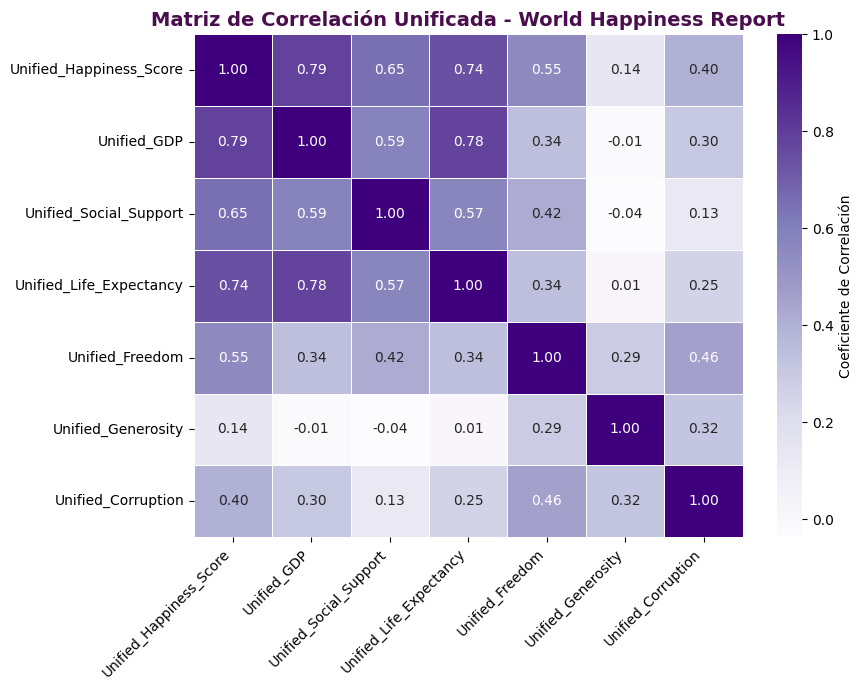

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_clean = df_flattened.copy()

df_clean['Unified_Happiness_Score'] = df_clean['Happiness Score'].fillna(
    df_clean['Happiness.Score']).fillna(df_clean['Score'])

df_clean['Unified_GDP'] = df_clean['Economy (GDP per Capita)'].fillna(
    df_clean['Economy..GDP.per.Capita.']).fillna(df_clean['GDP per capita'])

df_clean['Unified_Social_Support'] = df_clean['Family'].fillna(df_clean['Social support'])

df_clean['Unified_Life_Expectancy'] = df_clean['Health (Life Expectancy)'].fillna(
    df_clean['Health..Life.Expectancy.']).fillna(df_clean['Healthy life expectancy'])

df_clean['Unified_Freedom'] = df_clean['Freedom'].fillna(df_clean['Freedom to make life choices'])

df_clean['Unified_Generosity'] = df_clean['Generosity']

df_clean['Unified_Corruption'] = df_clean['Trust (Government Corruption)'].fillna(
    df_clean['Trust..Government.Corruption.']).fillna(df_clean['Perceptions of corruption'])

analysis_cols = [
    'Unified_Happiness_Score', 'Unified_GDP', 'Unified_Social_Support',
    'Unified_Life_Expectancy', 'Unified_Freedom', 'Unified_Generosity', 'Unified_Corruption'
]

df_analysis = df_clean[analysis_cols].copy()
df_analysis = df_analysis.fillna(df_analysis.mean())

print(" Dimensiones del Dataset Unificado para el Modelo ")
print(df_analysis.shape)
display(df_analysis.head())

# Matriz de correlación estilizada
plt.figure(figsize=(9, 7))
sns.heatmap(df_analysis.corr(), annot=True, cmap='Purples', fmt=".2f", linewidths=0.5, cbar_kws={'label': 'Coeficiente de Correlación'})
plt.title("Matriz de Correlación Unificada - World Happiness Report", fontsize=14, fontweight='bold', color='#4A0E4E')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Fase 3: Preparación de Características (Feature Engineering)

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Definir la variable objetivo (Target) y las características (Features) usando df_analysis
target_column = 'Unified_Happiness_Score'
feature_columns = [
    'Unified_GDP', 'Unified_Social_Support', 'Unified_Life_Expectancy',
    'Unified_Freedom', 'Unified_Generosity', 'Unified_Corruption'
]

X = df_analysis[feature_columns]
y = df_analysis[target_column]

# 2. Dividir el dataset en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Aplicar escalado estándar (StandardScaler) exclusivamente sobre el conjunto de entrenamiento
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("--- Fase 3 Completada con Éxito ---")
print(f"Dimensiones de X_train (Entrenamiento): {X_train.shape}")
print(f"Dimensiones de X_test (Prueba): {X_test.shape}")
print(f"Características seleccionadas: {feature_columns}")

--- Fase 3 Completada con Éxito ---
Dimensiones de X_train (Entrenamiento): (625, 6)
Dimensiones de X_test (Prueba): (157, 6)
Características seleccionadas: ['Unified_GDP', 'Unified_Social_Support', 'Unified_Life_Expectancy', 'Unified_Freedom', 'Unified_Generosity', 'Unified_Corruption']


Fase 4: Entrenamiento del Modelo de Regresión

In [16]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_scaled, y_train)

print(" Fase 4: Modelo Entrenado Exitosamente ")
print("Coeficientes (pesos) asignados a cada característica:")
for feature, coef in zip(feature_columns, model.coef_):
    print(f"- {feature}: {coef:.4f}")
print(f"Intercepto del modelo: {model.intercept_:.4f}")

 Fase 4: Modelo Entrenado Exitosamente 
Coeficientes (pesos) asignados a cada característica:
- Unified_GDP: 0.4480
- Unified_Social_Support: 0.2302
- Unified_Life_Expectancy: 0.2425
- Unified_Freedom: 0.2407
- Unified_Generosity: 0.0787
- Unified_Corruption: 0.0871
Intercepto del modelo: 5.3678


Fase 5: Evaluación, Métricas y Visualización

 Métricas de Evaluación del Modelo 
MAE  (Error Absoluto Medio): 0.4326
MSE  (Error Cuadrático Medio): 0.3232
RMSE (Raíz del Error Cuadrático Medio): 0.5685
R²   (Coeficiente de Determinación): 0.7494


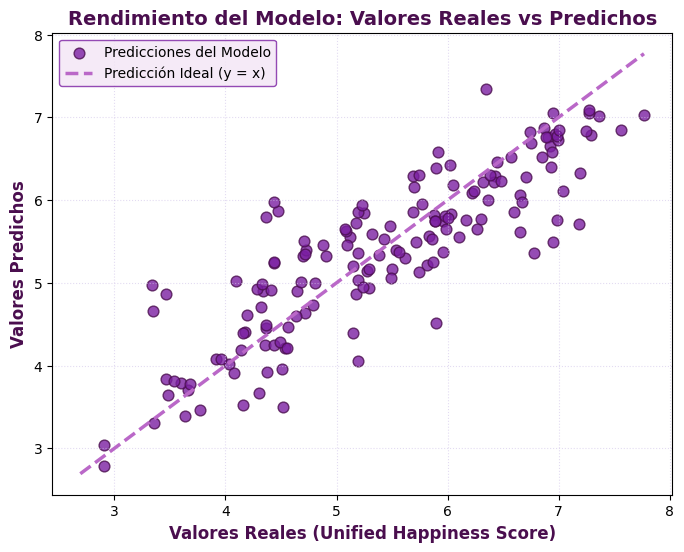


 Persistencia Completada 
Datos y predicciones almacenados exitosamente en la base de datos SQLite ('happiness_warehouse.db')


In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import sqlite3

y_pred = model.predict(X_test_scaled)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(" Métricas de Evaluación del Modelo ")
print(f"MAE  (Error Absoluto Medio): {mae:.4f}")
print(f"MSE  (Error Cuadrático Medio): {mse:.4f}")
print(f"RMSE (Raíz del Error Cuadrático Medio): {rmse:.4f}")
print(f"R²   (Coeficiente de Determinación): {r2:.4f}")

# Valores Reales vs Predichos
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='#7B1FA2', alpha=0.8, edgecolors='#4A0E4E', s=60, label='Predicciones del Modelo')
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='#BA68C8', linestyle='--', lw=2.5, label='Predicción Ideal (y = x)')
plt.xlabel('Valores Reales (Unified Happiness Score)', fontsize=12, color='#4A0E4E', fontweight='bold')
plt.ylabel('Valores Predichos', fontsize=12, color='#4A0E4E', fontweight='bold')
plt.title('Rendimiento del Modelo: Valores Reales vs Predichos', fontsize=14, fontweight='bold', color='#4A0E4E')
plt.legend(frameon=True, facecolor='#F3E5F5', edgecolor='#7B1FA2')
plt.grid(True, linestyle=':', alpha=0.6, color='#D1C4E9')
plt.show()

# Almacenamiento en SQLite
conn = sqlite3.connect('happiness_warehouse.db')
cursor = conn.cursor()

df_results = X_test.copy()
df_results['Actual_Happiness_Score'] = y_test.values
df_results['Predicted_Happiness_Score'] = y_pred

df_results.to_sql('model_predictions', conn, if_exists='replace', index=False)
conn.commit()
conn.close()

print("\n Persistencia Completada ")
print("Datos y predicciones almacenados exitosamente en la base de datos SQLite ('happiness_warehouse.db')")


Fase 6: Carga en Base de Datos (SQLite)

In [18]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('happiness_warehouse.db')
cursor = conn.cursor()

df_results = X_test.copy()
df_results['Actual_Happiness_Score'] = y_test.values
df_results['Predicted_Happiness_Score'] = y_pred

# DataFrame estructurado en una tablarelacional
table_name = 'model_predictions'
df_results.to_sql(table_name, conn, if_exists='replace', index=False)

# Verificación de la cargar de registros almacenados
query_check = f"SELECT * FROM {table_name} LIMIT 5;"
df_verification = pd.read_sql(query_check, conn)

conn.commit()
conn.close()

print(" Fase 6 Completada Exitosamente ")
print(f"Datos y predicciones almacenados en la tabla '{table_name}' de la base de datos 'happiness_warehouse.db'")
print("\nVista previa de los datos guardados en SQLite:")
display(df_verification)

 Fase 6 Completada Exitosamente 
Datos y predicciones almacenados en la tabla 'model_predictions' de la base de datos 'happiness_warehouse.db'

Vista previa de los datos guardados en SQLite:


,Unified_GDP,Unified_Social_Support,Unified_Life_Expectancy,Unified_Freedom,Unified_Generosity,Unified_Corruption,Actual_Happiness_Score,Predicted_Happiness_Score
0,1.35943,1.08113,0.77758,0.46823,0.22202,0.12275,7.039,6.111054
1,0.34193,0.76062,0.15010,0.23501,0.18386,0.05269,3.667,3.707928
2,0.91800,1.31400,0.67200,0.58500,0.30700,0.05000,4.471,5.868263
3,1.56391,1.21963,0.91894,0.61583,0.28034,0.37798,6.946,7.052559
4,1.24400,1.43300,0.88800,0.46400,0.26200,0.08200,7.190,6.323533
